In [1]:
import pandas as pd

users = pd.read_csv("../data/users.csv")
flights = pd.read_csv("../data/flights.csv")
hotels = pd.read_csv("../data/hotels.csv")

print(users.shape, flights.shape, hotels.shape)
users.head()

(1340, 5) (271888, 10) (40552, 8)


,code,company,name,gender,age
0,0,4You,Roy Braun,male,21
1,1,4You,Joseph Holsten,male,37
2,2,4You,Wilma Mcinnis,female,48
3,3,4You,Paula Daniel,female,23
4,4,4You,Patricia Carson,female,44


In [2]:
print(flights.head())
print(flights.info())
print(hotels.head())


   travelCode  userCode                from                  to  flightType  \
0           0         0         Recife (PE)  Florianopolis (SC)  firstClass   
1           0         0  Florianopolis (SC)         Recife (PE)  firstClass   
2           1         0       Brasilia (DF)  Florianopolis (SC)  firstClass   
3           1         0  Florianopolis (SC)       Brasilia (DF)  firstClass   
4           2         0        Aracaju (SE)       Salvador (BH)  firstClass   

     price  time  distance       agency        date  
0  1434.38  1.76    676.53  FlyingDrops  09/26/2019  
1  1292.29  1.76    676.53  FlyingDrops  09/30/2019  
2  1487.52  1.66    637.56      CloudFy  10/03/2019  
3  1127.36  1.66    637.56      CloudFy  10/04/2019  
4  1684.05  2.16    830.86      CloudFy  10/10/2019  
<class 'pandas.DataFrame'>
RangeIndex: 271888 entries, 0 to 271887
Data columns (total 10 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   travelCode  

In [3]:
for name, df in [("users", users), ("flights", flights), ("hotels", hotels)]:
    print(name, "missing:", df.isnull().sum().sum(), "duplicates:", df.duplicated().sum())

flights["date"] = pd.to_datetime(flights["date"], format="%m/%d/%Y")
hotels["date"] = pd.to_datetime(hotels["date"], format="%m/%d/%Y")
print(flights["date"].min(), flights["date"].max())
print(flights["flightType"].value_counts())

users missing: 0 duplicates: 0
flights missing: 0 duplicates: 0
hotels missing: 0 duplicates: 0
2019-09-26 00:00:00 2023-07-24 00:00:00
flightType
firstClass    116418
premium        78004
economic       77466
Name: count, dtype: int64


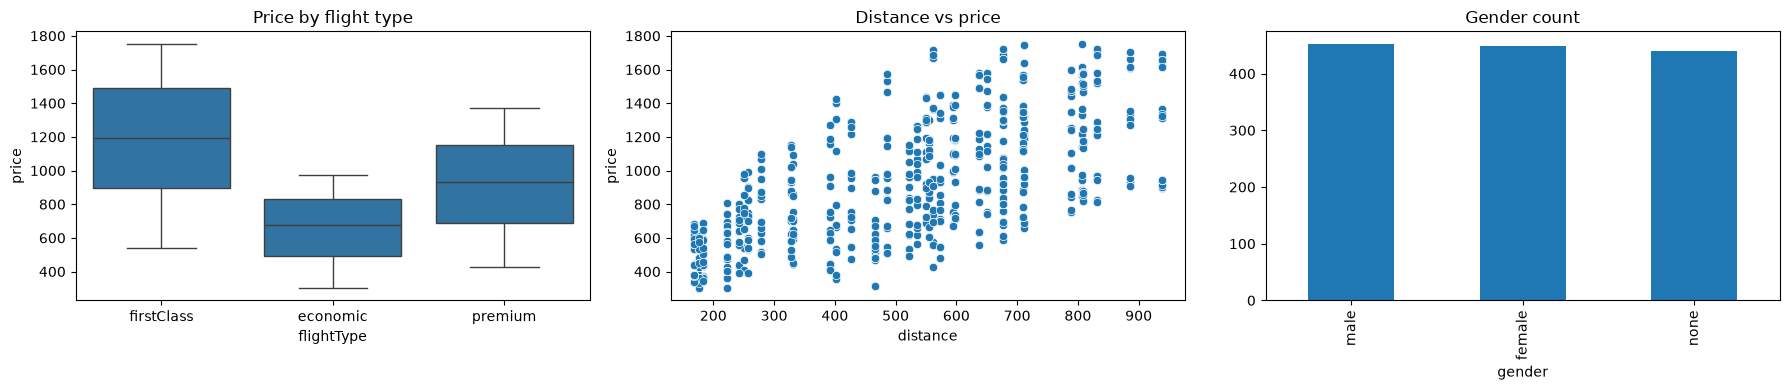

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(1, 3, figsize=(18, 4))

sns.boxplot(data=flights, x="flightType", y="price", ax=ax[0])
ax[0].set_title("Price by flight type")

sns.scatterplot(data=flights.sample(5000, random_state=42), x="distance", y="price", ax=ax[1])
ax[1].set_title("Distance vs price")

users["gender"].value_counts().plot(kind="bar", ax=ax[2])
ax[2].set_title("Gender count")

plt.tight_layout()
plt.show()

In [5]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

df = flights.copy()
df["month"] = df["date"].dt.month
df["dayofweek"] = df["date"].dt.dayofweek

X = pd.get_dummies(df[["from", "to", "flightType", "agency", "distance", "time", "month", "dayofweek"]])
y = df["price"]

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)

for name, m in [("LinearRegression", LinearRegression()),
                ("RandomForest", RandomForestRegressor(n_estimators=50, n_jobs=-1, random_state=42))]:
    m.fit(X_tr, y_tr)
    p = m.predict(X_te)
    print(name, "RMSE:", round(np.sqrt(mean_squared_error(y_te, p)), 2), "R2:", round(r2_score(y_te, p), 4))

C:\Users\GARV\AppData\Local\Temp\ipykernel_20268\458404336.py:9: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["dayofweek"] = df["date"].dt.dayofweek


LinearRegression RMSE: 103.15 R2: 0.9193
RandomForest RMSE: 0.02 R2: 1.0


In [6]:
flights["price_per_km"] = flights["price"] / flights["distance"]
print(flights.groupby("flightType")["price_per_km"].describe()[["mean", "std", "min", "max"]])


                mean       std       min       max
flightType                                        
economic    1.316596  0.387704  0.672571  2.269825
firstClass  2.344586  0.662624  1.178533  4.069968
premium     1.819102  0.511452  0.987067  3.192129


In [7]:
imp = pd.Series(m.feature_importances_, index=X.columns).sort_values(ascending=False)
print(imp.head(10))

flightType_firstClass      0.296509
time                       0.238557
distance                   0.235690
flightType_premium         0.069674
from_Florianopolis (SC)    0.047287
to_Aracaju (SE)            0.021508
to_Florianopolis (SC)      0.015778
from_Sao Paulo (SP)        0.011933
from_Brasilia (DF)         0.009199
to_Sao Paulo (SP)          0.009074
dtype: float64


In [8]:
g = flights.groupby(["from", "to", "flightType"])["price"].agg(["count", "std"])
print(g["std"].describe())

count    210.000000
mean      22.965595
std       16.240817
min        0.045012
25%        8.614149
50%       20.082885
75%       34.863162
max       65.474478
Name: std, dtype: float64


In [9]:
df = df.sort_values("date")
cut = int(len(df) * 0.8)
train, test = df.iloc[:cut], df.iloc[cut:]

cols = ["from", "to", "flightType", "agency", "distance", "time", "month", "day_of_week"]
df["day_of_week"] = df["date"].dt.day_of_week
train, test = df.iloc[:cut], df.iloc[cut:]

Xt = pd.get_dummies(train[cols]); Xs = pd.get_dummies(test[cols]).reindex(columns=Xt.columns, fill_value=0)

for name, mdl in [("LinearRegression", LinearRegression()),
                  ("RandomForest", RandomForestRegressor(n_estimators=50, n_jobs=-1, random_state=42))]:
    mdl.fit(Xt, train["price"])
    p = mdl.predict(Xs)
    print(name, "RMSE:", round(np.sqrt(mean_squared_error(test["price"], p)), 2), "R2:", round(r2_score(test["price"], p), 4))

LinearRegression RMSE: 102.16 R2: 0.9208
RandomForest RMSE: 0.02 R2: 1.0


In [10]:
g2 = flights.groupby(["from", "to", "flightType", "agency"])["price"].std()
print(g2.describe())

count    490.0
mean       0.0
std        0.0
min        0.0
25%        0.0
50%        0.0
75%        0.0
max        0.0
Name: price, dtype: float64
